In [1]:
import sys

print("Python version:", sys.version)
print("Python is ready!")

Python version: 3.11.4 (tags/v3.11.4:d2340ef, Jun  7 2023, 05:45:37) [MSC v.1934 64 bit (AMD64)]
Python is ready!


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl joblib streamlit


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpy


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import openpyxl
import joblib
import streamlit as st

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Streamlit:", st.__version__)

All libraries imported successfully!
Pandas: 2.3.3
Scikit-learn: 1.8.0
Streamlit: 1.60.0


In [4]:
import pandas as pd

df = pd.read_csv("../dataset/Bank_Churn.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (10000, 13)


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,Num Of Products,Has Credit Card,Is Active Member,Estimated Salary,Churn
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerId        10000 non-null  int64  
 1   Surname           10000 non-null  object 
 2   CreditScore       10000 non-null  int64  
 3   Geography         10000 non-null  object 
 4   Gender            10000 non-null  object 
 5   Age               10000 non-null  int64  
 6   Tenure            10000 non-null  int64  
 7   Balance           10000 non-null  float64
 8   Num Of Products   10000 non-null  int64  
 9   Has Credit Card   10000 non-null  int64  
 10  Is Active Member  10000 non-null  int64  
 11  Estimated Salary  10000 non-null  float64
 12  Churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 1015.8+ KB

Missing values:
CustomerId          0
Surname             0
CreditScore         0
Geography           0
Gender           

In [6]:
duplicates = df.duplicated().sum()

print("Total duplicate rows:", duplicates)


Total duplicate rows: 0


In [7]:
churn_counts = df['Churn'].value_counts()

print("Churn Distribution:")
print(churn_counts)

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn Distribution:
Churn
0    7963
1    2037
Name: count, dtype: int64

Churn Percentage:
Churn
0    79.63
1    20.37
Name: proportion, dtype: float64


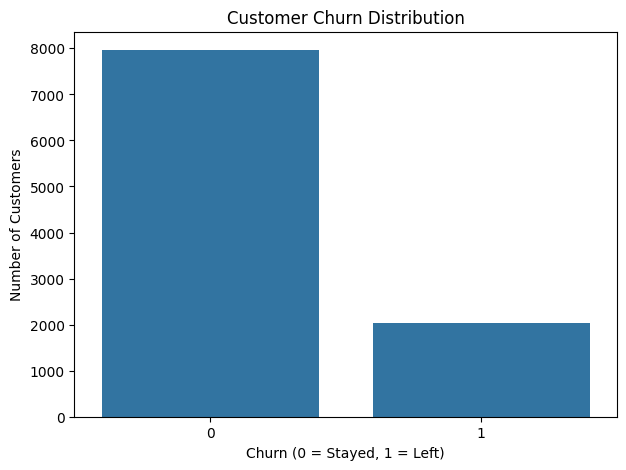

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn (0 = Stayed, 1 = Left)')
plt.ylabel('Number of Customers')

plt.show()

In [9]:
average_age = df.groupby('Churn')['Age'].mean()

print("Average Customer Age:")
print(average_age)

Average Customer Age:
Churn
0    37.408389
1    44.837997
Name: Age, dtype: float64


In [10]:
average_balance = df.groupby('Churn')['Balance'].mean()

print("Average Bank Balance:")
print(average_balance)

Average Bank Balance:
Churn
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64


In [11]:
geography_churn = pd.crosstab(
    df['Geography'],
    df['Churn'],
    normalize='index'
) * 100

print(geography_churn)

Churn              0          1
Geography                      
France     83.845233  16.154767
Germany    67.556796  32.443204
Spain      83.326605  16.673395


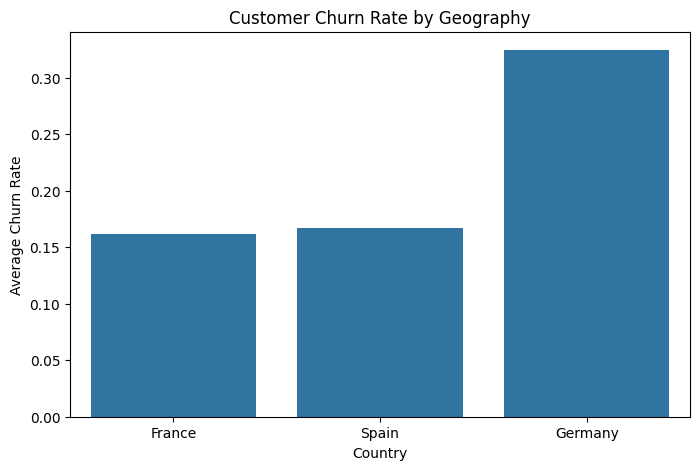

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Geography',
    y='Churn',
    errorbar=None
)

plt.title('Customer Churn Rate by Geography')
plt.xlabel('Country')
plt.ylabel('Average Churn Rate')
plt.show()

In [13]:
gender_churn = pd.crosstab(
    df['Gender'],
    df['Churn'],
    normalize='index'
) * 100

print("Churn Rate by Gender:")
print(gender_churn)

Churn Rate by Gender:
Churn           0          1
Gender                      
Female  74.928461  25.071539
Male    83.544072  16.455928


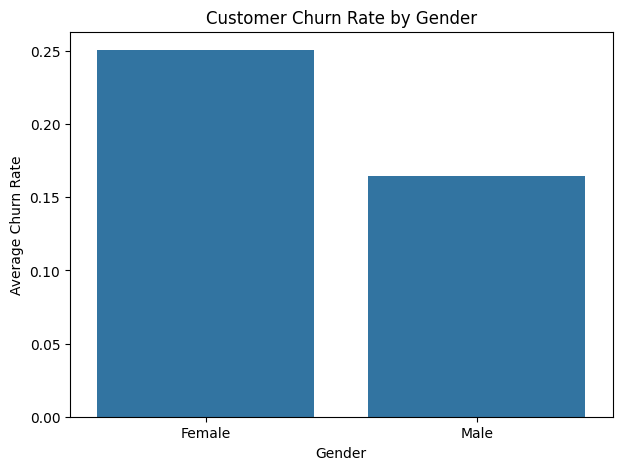

In [14]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x='Gender',
    y='Churn',
    errorbar=None
)

plt.title('Customer Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Churn Rate')
plt.show()

In [15]:
active_churn = pd.crosstab(
    df['Is Active Member'],
    df['Churn'],
    normalize='index'
) * 100

print("Churn Rate by Active Membership:")
print(active_churn)

Churn Rate by Active Membership:
Churn                     0          1
Is Active Member                      
0                 73.149103  26.850897
1                 85.730926  14.269074


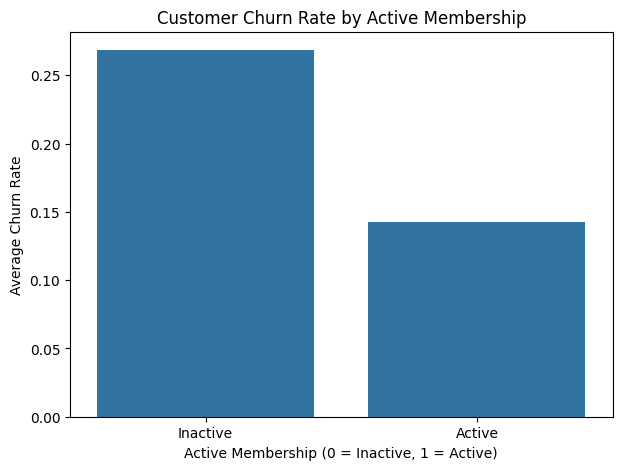

In [16]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x='Is Active Member',
    y='Churn',
    errorbar=None
)

plt.title('Customer Churn Rate by Active Membership')
plt.xlabel('Active Membership (0 = Inactive, 1 = Active)')
plt.ylabel('Average Churn Rate')
plt.xticks([0, 1], ['Inactive', 'Active'])
plt.show()

## Exploratory Data Analysis (EDA) Findings

1. The overall customer churn rate is 20.37%.
2. Customers who left had a higher average age (44.84 years) than customers who stayed (37.41 years).
3. Customers who left had a higher average bank balance (91,108.54) than customers who stayed (72,745.30).
4. Germany had the highest churn rate (32.44%).
5. Female customers had a higher churn rate (25.07%) than male customers (16.46%).
6. Inactive members had a higher churn rate (26.85%) than active members (14.27%).

Conclusion:
Age, geography, gender, account balance, and active membership
show differences between customers who stayed and those who left.
These patterns may help the bank identify customers at risk of churn.

In [17]:
X = df.drop(['CustomerId', 'Surname', 'Churn'], axis=1)
y = df['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (10000, 10)
Target shape: (10000,)

Feature columns:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'Num Of Products', 'Has Credit Card', 'Is Active Member', 'Estimated Salary']


In [18]:
X = pd.get_dummies(
    X,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)

print("Encoded Features Shape:", X.shape)
print("\nEncoded Columns:")
print(X.columns.tolist())

Encoded Features Shape: (10000, 11)

Encoded Columns:
['CreditScore', 'Age', 'Tenure', 'Balance', 'Num Of Products', 'Has Credit Card', 'Is Active Member', 'Estimated Salary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (8000, 11)
Testing Features: (2000, 11)
Training Target: (8000,)
Testing Target: (2000,)


In [20]:
from sklearn.preprocessing import StandardScaler

scale_columns = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'Num Of Products',
    'Estimated Salary'
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_columns] = scaler.fit_transform(
    X_train[scale_columns]
)

X_test_scaled[scale_columns] = scaler.transform(
    X_test[scale_columns]
)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)
print("\nScaling completed successfully!")

Training data scaled: (8000, 11)
Testing data scaled: (2000, 11)

Scaling completed successfully!


In [21]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [23]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("First 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred_lr[:20])

First 20 Actual Values:
[0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0]

First 20 Predicted Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0]


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

Logistic Regression Results
Accuracy: 0.808
Precision: 0.5891472868217055
Recall: 0.18673218673218672
F1 Score: 0.2835820895522388


In [25]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1540   53]
 [ 331   76]]


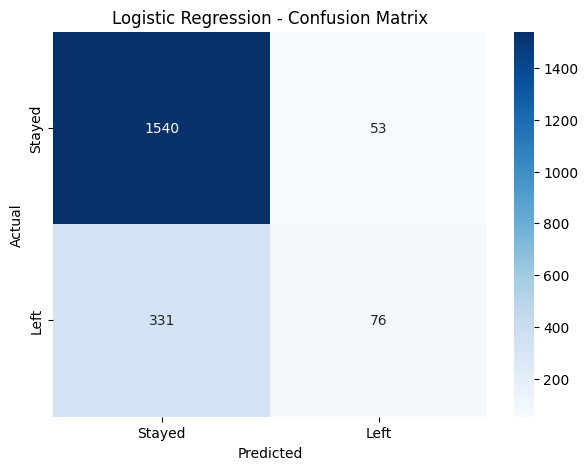

In [26]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [27]:
lr_balanced = LogisticRegression(
    class_weight='balanced',
    random_state=42
)

lr_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = lr_balanced.predict(X_test_scaled)

print("Balanced Logistic Regression trained!")

Balanced Logistic Regression trained!


In [28]:
print("Balanced Logistic Regression Results")

print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced))
print("Recall:", recall_score(y_test, y_pred_balanced))
print("F1 Score:", f1_score(y_test, y_pred_balanced))

Balanced Logistic Regression Results
Accuracy: 0.7135
Precision: 0.38722826086956524
Recall: 0.7002457002457002
F1 Score: 0.49868766404199477


In [29]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print("Balanced Logistic Regression Confusion Matrix:")
print(cm_balanced)

Balanced Logistic Regression Confusion Matrix:
[[1142  451]
 [ 122  285]]


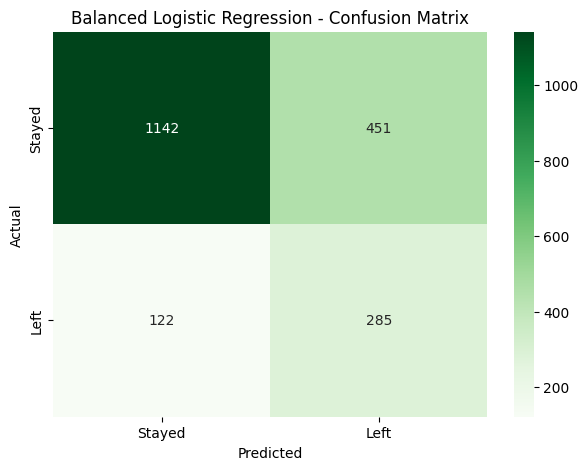

In [30]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Balanced Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [31]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [32]:
y_pred_dt = dt_model.predict(X_test)

print("First 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Decision Tree Predictions:")
print(y_pred_dt[:20])

First 20 Actual Values:
[0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0]

First 20 Decision Tree Predictions:
[0 0 0 0 0 1 0 1 1 0 1 1 0 0 0 0 0 0 1 1]


In [33]:
print("Decision Tree Results")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

Decision Tree Results
Accuracy: 0.77
Precision: 0.46074074074074073
Recall: 0.7641277641277642
F1 Score: 0.5748613678373382


In [34]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

Decision Tree Confusion Matrix:
[[1229  364]
 [  96  311]]


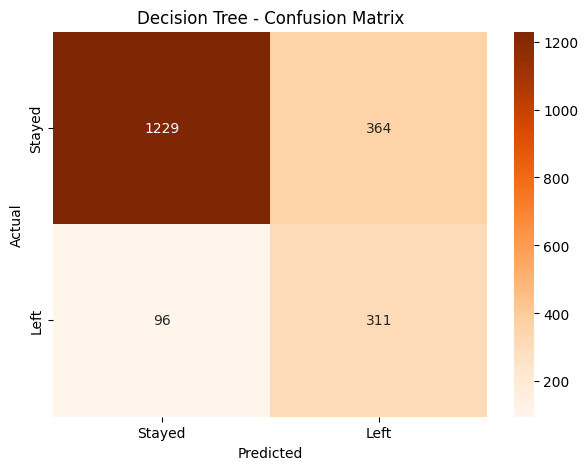

In [35]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [37]:
y_pred_rf = rf_model.predict(X_test)

print("First 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Random Forest Predictions:")
print(y_pred_rf[:20])

First 20 Actual Values:
[0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0]

First 20 Random Forest Predictions:
[0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 1]


In [38]:
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Random Forest Results
Accuracy: 0.8335
Precision: 0.5833333333333334
Recall: 0.6363636363636364
F1 Score: 0.6086956521739131


In [39]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[1408  185]
 [ 148  259]]


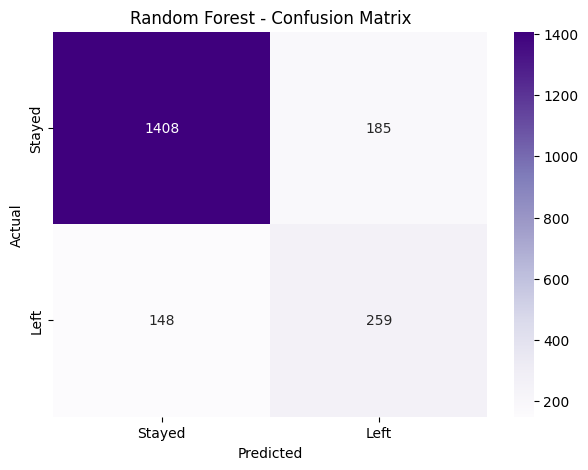

In [40]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [41]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

print(model_comparison.round(4))

                          Model  Accuracy  Precision  Recall  F1 Score
0           Logistic Regression    0.8080     0.5891  0.1867    0.2836
1  Balanced Logistic Regression    0.7135     0.3872  0.7002    0.4987
2                 Decision Tree    0.7700     0.4607  0.7641    0.5749
3                 Random Forest    0.8335     0.5833  0.6364    0.6087


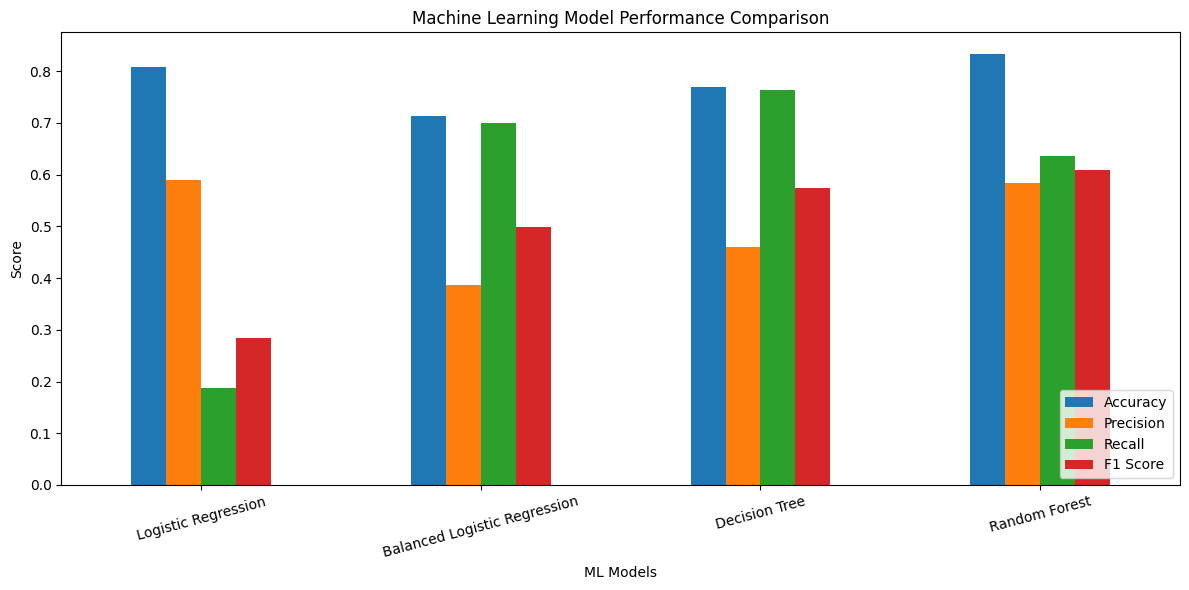

In [42]:
model_comparison.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('ML Models')
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [43]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

              Feature  Importance
1                 Age    0.315933
4     Num Of Products    0.202163
3             Balance    0.120247
7    Estimated Salary    0.083935
0         CreditScore    0.082671
6    Is Active Member    0.053359
8   Geography_Germany    0.051830
2              Tenure    0.046362
10        Gender_Male    0.022493
9     Geography_Spain    0.010682
5     Has Credit Card    0.010325


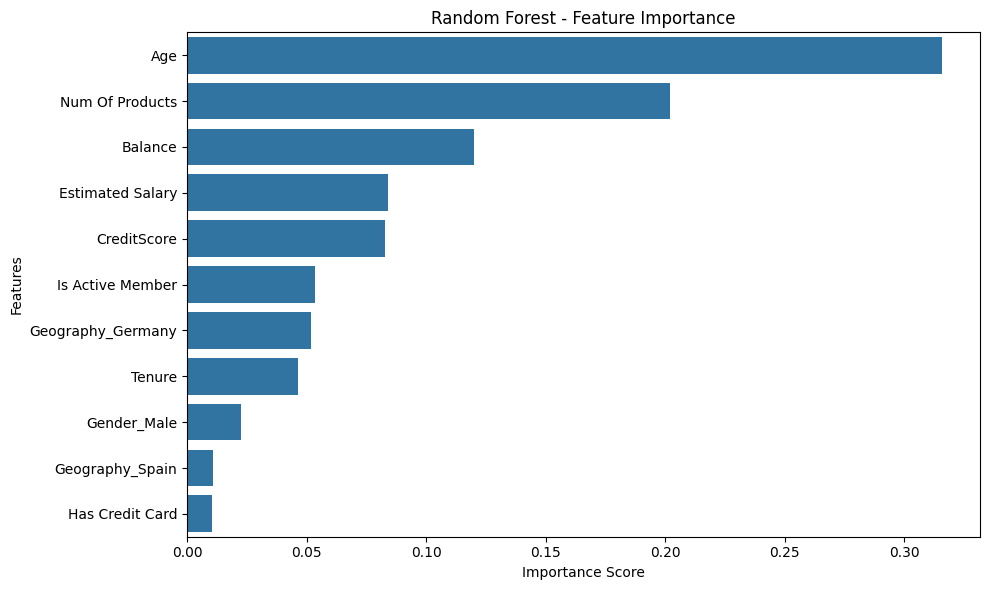

In [44]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## Feature Importance Analysis

The Random Forest model identified the following important features:

1. Age (31.59%) was the most important feature.
2. Number of Products (20.22%) was the second most important.
3. Balance (12.02%) was the third most important.
4. Estimated Salary (8.39%) and Credit Score (8.27%) also contributed to model predictions.

Conclusion:
Age and the number of products were the two most influential
features in the model's churn predictions.

Feature importance indicates the model's reliance on these
features, not a causal relationship with customer churn.

In [45]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/random_forest_churn_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [46]:
joblib.dump(
    X_train.columns.tolist(),
    "../models/feature_columns.pkl"
)

print("Feature columns saved successfully!")

Feature columns saved successfully!


In [48]:
test_results = df.loc[
    X_test.index,
    ['CustomerId', 'Geography', 'Gender', 'Age',
     'Balance', 'Is Active Member', 'Churn']
].copy()

test_results['Predicted_Churn'] = y_pred_rf

test_results['Churn_Probability'] = rf_model.predict_proba(
    X_test
)[:, 1]

print(test_results.head())

      CustomerId Geography  Gender  Age    Balance  Is Active Member  Churn  \
5702    15749540    France    Male   36       0.00                 0      0   
3667    15807340   Germany    Male   33  131023.76                 0      0   
1617    15801062     Spain  Female   40       0.00                 1      0   
5673    15572801     Spain    Male   34  139393.19                 0      0   
4272    15600708     Spain  Female   34   77826.80                 1      0   

      Predicted_Churn  Churn_Probability  
5702                0           0.109269  
3667                0           0.182858  
1617                0           0.150465  
5673                0           0.114142  
4272                0           0.282445  


In [49]:
total_customers = len(test_results)

potential_churn = (
    test_results['Predicted_Churn'] == 1
).sum()

actual_churn = (
    test_results['Churn'] == 1
).sum()

correctly_identified = (
    (test_results['Churn'] == 1) &
    (test_results['Predicted_Churn'] == 1)
).sum()

predicted_churn_percentage = (
    potential_churn / total_customers
) * 100

print("Total Customers:", total_customers)
print("Potential Churn Customers:", potential_churn)
print("Actual Churn Customers:", actual_churn)
print("Correctly Identified Churn Customers:", correctly_identified)
print("Predicted Churn Percentage:", round(predicted_churn_percentage, 2))

Total Customers: 2000
Potential Churn Customers: 444
Actual Churn Customers: 407
Correctly Identified Churn Customers: 259
Predicted Churn Percentage: 22.2


In [50]:
business_summary = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Potential Churn Customers',
        'Actual Churn Customers',
        'Correctly Identified Churn Customers',
        'Predicted Churn Percentage'
    ],
    'Value': [
        total_customers,
        potential_churn,
        actual_churn,
        correctly_identified,
        round(predicted_churn_percentage, 2)
    ]
})

print(business_summary)

                                 Metric   Value
0                       Total Customers  2000.0
1             Potential Churn Customers   444.0
2                Actual Churn Customers   407.0
3  Correctly Identified Churn Customers   259.0
4            Predicted Churn Percentage    22.2


In [51]:
with pd.ExcelWriter(
    "../reports/Customer_Churn_Business_Report.xlsx",
    engine="openpyxl"
) as writer:

    business_summary.to_excel(
        writer,
        sheet_name="Business Summary",
        index=False
    )

    model_comparison.to_excel(
        writer,
        sheet_name="Model Comparison",
        index=False
    )

    test_results.to_excel(
        writer,
        sheet_name="Test Predictions",
        index=False
    )

print("Excel Business Report created successfully!")

Excel Business Report created successfully!


In [52]:
print(os.listdir("../reports"))

['Customer_Churn_Business_Report.xlsx']


In [53]:
excel_file = pd.ExcelFile(
    "../reports/Customer_Churn_Business_Report.xlsx"
)

print(excel_file.sheet_names)

['Business Summary', 'Model Comparison', 'Test Predictions']


In [55]:
print(os.listdir(".."))

['.gitignore', 'app.py', 'dataset', 'models', 'notebooks', 'README.md', 'reports', 'requirements.txt']
